# Деревья и ансамбли. Несбалансированная классификация

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "02_trees"
OUT.mkdir(exist_ok=True, parents=True)

## Данные и базовые ансамбли

2200 объектов, 12 признаков, около 10% положительного класса и 2% шума в метках. Разбиение 60/20/20. Метрики: macro-F1, recall и average precision.

Формы: (1320, 12) (440, 12) (440, 12) доли класса 1: 0.10984848484848485 0.11136363636363636 0.10909090909090909


,model,macro_f1,recall_positive,AP,seconds
0,tree,0.83500,0.57143,0.66707,0.00707
1,bagging,0.85905,0.69388,0.84864,0.20223
2,forest,0.87882,0.69388,0.85933,0.09906
3,AdaBoost,0.84702,0.61224,0.82097,0.07679
4,GradientBoosting,0.83371,0.59184,0.85082,0.09532
5,HistGradientBoosting,0.90625,0.75510,0.86532,0.72209
6,stacking,0.89375,0.73469,0.87570,0.03667


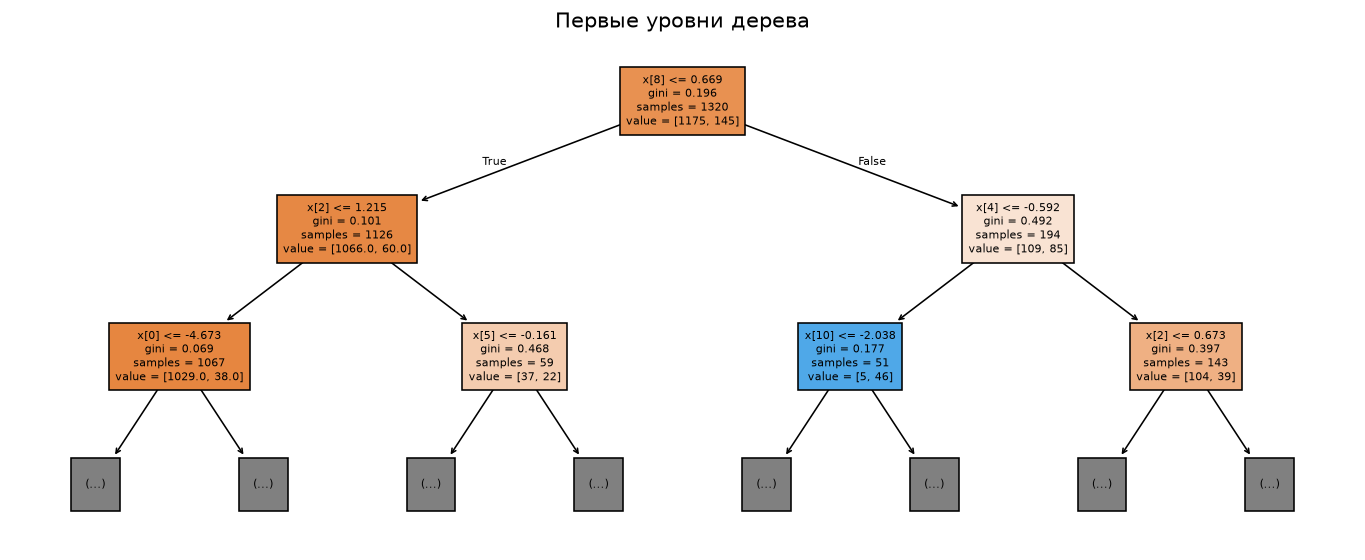

CV macro-F1: [0.80335534 0.84007333 0.74917846] mean/std: 0.7975357068177903 0.045726035034592154


В stacking метамодель обучается на out-of-fold прогнозах внутренних трёх фолдов. Validation и test в обучение метамодели не включаются.

In [2]:
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
from sklearn.inspection import permutation_importance

X, y = make_classification(
    n_samples=2200,
    n_features=12,
    n_informative=6,
    n_redundant=3,
    weights=[0.9, 0.1],
    flip_y=0.02,
    random_state=11,
)
train, val, test = split3(X, y)
xt, yt = [z.numpy() for z in train]
xv, yv = [z.numpy() for z in val]
xe, ye = [z.numpy() for z in test]
print(
    "Формы:",
    xt.shape,
    xv.shape,
    xe.shape,
    "доли класса 1:",
    yt.mean(),
    yv.mean(),
    ye.mean(),
)
candidates = {
    "tree": DecisionTreeClassifier(max_depth=3, random_state=11),
    "bagging": BaggingClassifier(n_estimators=40, random_state=11, n_jobs=1),
    "forest": RandomForestClassifier(
        n_estimators=80, max_depth=8, random_state=11, n_jobs=1
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=60, random_state=11),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=60, max_depth=2, random_state=11
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=60, random_state=11
    ),
}
candidates["stacking"] = StackingClassifier(
    estimators=[
        ("linear", LogisticRegression(max_iter=1000)),
        ("tree", DecisionTreeClassifier(max_depth=4, random_state=11)),
        ("knn", KNeighborsClassifier(7)),
    ],
    final_estimator=LogisticRegression(),
    cv=3,
    n_jobs=1,
)
rows = []
for name, m in candidates.items():
    start = time.perf_counter()
    m.fit(xt, yt)
    p = m.predict_proba(xv)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append(
        {
            "model": name,
            "macro_f1": f1_score(yv, pred, average="macro"),
            "recall_positive": recall_score(yv, pred),
            "AP": average_precision_score(yv, p),
            "seconds": time.perf_counter() - start,
        }
    )
table(rows, OUT, "baseline_ensembles")
plt.figure(figsize=(12, 5))
plot_tree(candidates["tree"], max_depth=2, filled=True, fontsize=7)
plt.title("Первые уровни дерева")
showfig("tree_splits", OUT)
cv = cross_val_score(
    candidates["forest"],
    xt,
    yt,
    cv=StratifiedKFold(3, shuffle=True, random_state=11),
    scoring="f1_macro",
)
print("CV macro-F1:", cv, "mean/std:", cv.mean(), cv.std(ddof=1))
note(
    "В stacking метамодель обучается на out-of-fold прогнозах внутренних трёх фолдов. Validation и test в обучение метамодели не включаются."
)

## Вариант 11. Веса, sampling и порог

Сравниваю обычный random forest, class_weight, oversampling, undersampling и подбор порога по validation. Балансировку делаю только на train.

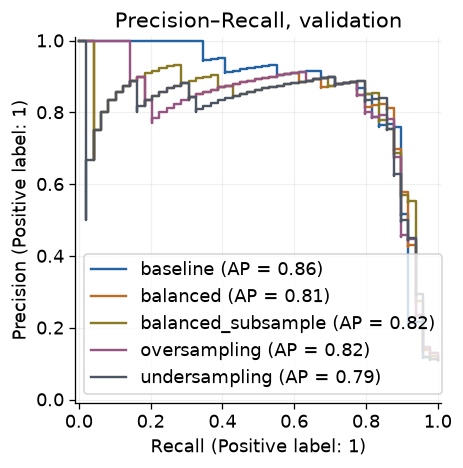

,method,threshold,train_size,precision,recall,f1_positive,macro_f1,AP
0,baseline,0.5,1320,0.89189,0.67347,0.76744,0.87113,0.86077
1,balanced,0.5,1320,0.81132,0.87755,0.84314,0.91129,0.81042
2,balanced_subsample,0.5,1320,0.84444,0.77551,0.80851,0.89280,0.81694
3,oversampling,0.5,2350,0.78431,0.81633,0.80000,0.88718,0.81896
4,undersampling,0.5,290,0.45098,0.93878,0.60927,0.76417,0.79119
5,validation_threshold,0.4,1320,0.85106,0.81633,0.83333,0.90646,0.86077


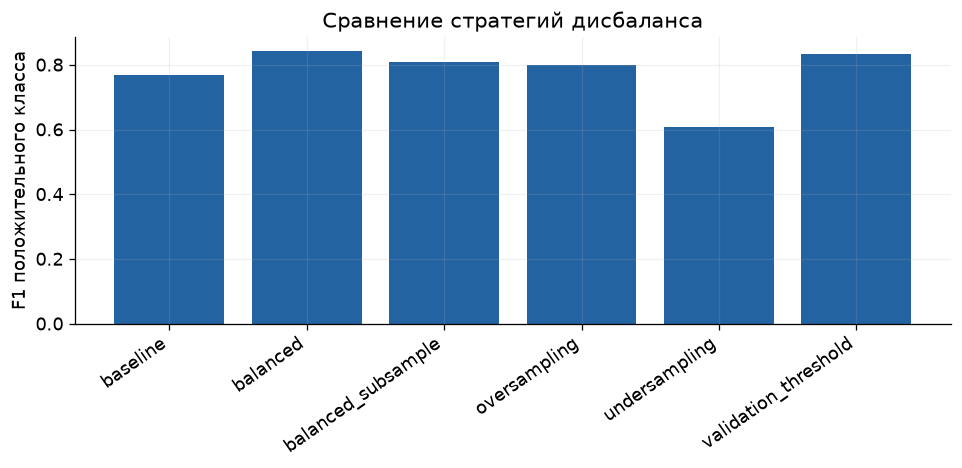

Финальный test: {'method': 'balanced', 'threshold': 0.5, 'F1': 0.7916666666666666, 'precision': 0.7916666666666666, 'recall': 0.7916666666666666, 'AP': 0.8028148193413369}


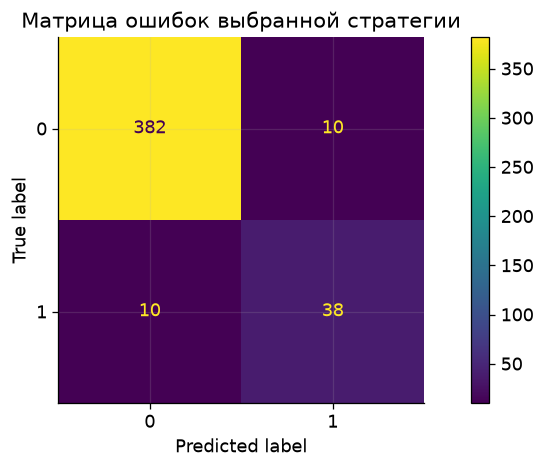

,index,true,probability,predicted,error
0,25,1,0.46404,0,FN
1,61,1,0.15094,0,FN
2,79,1,0.32083,0,FN
3,85,0,0.68759,1,FP
4,111,1,0.05981,0,FN
5,112,1,0.04851,0,FN
6,122,0,0.75200,1,FP
7,209,1,0.46953,0,FN
8,210,0,0.53781,1,FP
9,258,1,0.05665,0,FN


По validation выбран метод balanced, порог 0.500. Веса классов и sampling меняют обучение, а порог меняет рабочую точку уже обученного классификатора. Увеличение recall оплачивается возможным ростом FP. Высокая accuracy при доле редкого класса около 10% может скрывать его пропуск.

In [3]:
rng = np.random.default_rng(11)
pos = np.flatnonzero(yt == 1)
neg = np.flatnonzero(yt == 0)
over = np.r_[neg, rng.choice(pos, len(neg), replace=True)]
under = np.r_[pos, rng.choice(neg, len(pos), replace=False)]
configs = [
    ("baseline", None, np.arange(len(yt))),
    ("balanced", "balanced", np.arange(len(yt))),
    ("balanced_subsample", "balanced_subsample", np.arange(len(yt))),
    ("oversampling", None, over),
    ("undersampling", None, under),
]
rows = []
models = {}
thresholds = {}
for name, weight, ids in configs:
    m = RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight=weight, random_state=11, n_jobs=1
    ).fit(xt[ids], yt[ids])
    models[name] = m
    p = m.predict_proba(xv)[:, 1]
    pred = p >= 0.5
    rows.append(
        {
            "method": name,
            "threshold": 0.5,
            "train_size": len(ids),
            "precision": precision_score(yv, pred, zero_division=0),
            "recall": recall_score(yv, pred),
            "f1_positive": f1_score(yv, pred),
            "macro_f1": f1_score(yv, pred, average="macro"),
            "AP": average_precision_score(yv, p),
        }
    )
    PrecisionRecallDisplay.from_predictions(yv, p, name=name, ax=plt.gca())
p = models["baseline"].predict_proba(xv)[:, 1]
grid = np.linspace(0.05, 0.95, 37)
scores = [f1_score(yv, p >= t) for t in grid]
threshold = float(grid[np.argmax(scores)])
pred = p >= threshold
rows.append(
    {
        "method": "validation_threshold",
        "threshold": threshold,
        "train_size": len(yt),
        "precision": precision_score(yv, pred),
        "recall": recall_score(yv, pred),
        "f1_positive": f1_score(yv, pred),
        "macro_f1": f1_score(yv, pred, average="macro"),
        "AP": average_precision_score(yv, p),
    }
)
plt.title("Precision–Recall, validation")
showfig("precision_recall", OUT)
df = table(rows, OUT)
plt.bar(df.method, df.f1_positive)
plt.xticks(rotation=35, ha="right")
plt.ylabel("F1 положительного класса")
plt.title("Сравнение стратегий дисбаланса")
showfig("imbalance_comparison", OUT)
winner = df.sort_values("f1_positive", ascending=False).iloc[0]
name = winner["method"]
m = models["baseline"] if name == "validation_threshold" else models[name]
p = m.predict_proba(xe)[:, 1]
pred = p >= float(winner.threshold)
print(
    "Финальный test:",
    {
        "method": name,
        "threshold": float(winner.threshold),
        "F1": f1_score(ye, pred),
        "precision": precision_score(ye, pred),
        "recall": recall_score(ye, pred),
        "AP": average_precision_score(ye, p),
    },
)
ConfusionMatrixDisplay.from_predictions(ye, pred)
plt.title("Матрица ошибок выбранной стратегии")
showfig("test_confusion", OUT)
ids = np.flatnonzero(pred != ye)[:10]
table(
    [
        {
            "index": int(i),
            "true": int(ye[i]),
            "probability": p[i],
            "predicted": int(pred[i]),
            "error": "FN" if ye[i] else "FP",
        }
        for i in ids
    ],
    OUT,
    "errors",
)
note(
    f"По validation выбран метод {name}, порог {winner.threshold:.3f}. Веса классов и sampling меняют обучение, а порог меняет рабочую точку уже обученного классификатора. Увеличение recall оплачивается возможным ростом FP. Высокая accuracy при доле редкого класса около 10% может скрывать его пропуск."
)

## Интерпретация признаков и ограничений

Сравнение impurity importance и permutation importance, путь одного объекта по дереву.

In [4]:
forest = models["baseline"]
imp = permutation_importance(
    forest, xv, yv, n_repeats=4, random_state=11, scoring="f1_macro"
)
table(
    {
        "feature": np.arange(12),
        "impurity": forest.feature_importances_,
        "permutation": imp.importances_mean,
    },
    OUT,
    "importance",
)
tree = candidates["tree"]
path = tree.decision_path(xe[:1]).indices
print("Узлы пути первого объекта:", path.tolist(), "лист:", int(tree.apply(xe[:1])[0]))
note(
    "Коррелированные признаки могут распределять важность между собой. Permutation importance оценивает ухудшение на фиксированной validation-выборке и тоже зависит от корреляций. Ошибки FP/FN отражают перекрытие классов, шум меток и выбранную стоимость ошибок."
)

,feature,impurity,permutation
0,0,0.08029,0.01961
1,1,0.03463,0.00523
2,2,0.10707,0.05723
3,3,0.02420,-0.00515
4,4,0.12138,0.07296
5,5,0.11869,0.00915
6,6,0.06148,0.00150
7,7,0.07422,0.00876
8,8,0.22386,0.25032
9,9,0.05296,-0.01159


Узлы пути первого объекта: [0, 1, 2, 4] лист: 4


Коррелированные признаки могут распределять важность между собой. Permutation importance оценивает ухудшение на фиксированной validation-выборке и тоже зависит от корреляций. Ошибки FP/FN отражают перекрытие классов, шум меток и выбранную стоимость ошибок.

## Ответы на контрольные вопросы

1. Bagging усредняет ошибки разных обучающих выборок. При неполной корреляции ошибок дисперсия усреднения меньше дисперсии отдельной модели.

2. Boosting обучает модели последовательно с учётом ошибок текущего ансамбля; bagging допускает независимое обучение на bootstrap-выборках.

3. Out-of-fold предсказания исключают ситуацию, когда метамодель видит слишком оптимистичные ответы базовой модели на её обучающих объектах.

4. Корреляция может распределить важность между признаками или позволить одному заменить другой. Важность зависит от метода оценки и данных.

5. Глубокое дерево точнее подгоняет train, но чаще запоминает шум; ограничение глубины контролирует сложность.